# Airline Loyalty Churn: Retention Prioritization

**Business question:** Which airline loyalty members are most likely to cancel in the near future, and which high-value customers should the retention team contact first?

The objective is not only to predict churn, but to help the airline prioritize limited retention offers for customers with the highest churn risk and customer value.

This is a retrospective portfolio project using historical cancellation labels. Results and ROI figures are illustrative, not a live airline forecast.

In [58]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

In [59]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    RocCurveDisplay
)

sns.set_theme(style="whitegrid")

## Data
Load the two Maven Analytics CSV files from `DATA`, the notebook folder, or upload them when running in Colab.

In [60]:
required_files = ["Customer Flight Activity.csv", "Customer Loyalty History.csv"]
search_dirs = [Path.cwd(), Path("DATA"), Path("../DATA")]
data_paths = {
    filename: next(
        (folder / filename for folder in search_dirs if (folder / filename).is_file()),
        None,
    )
    for filename in required_files
}
missing_files = [filename for filename, path in data_paths.items() if path is None]

if missing_files:
    try:
        from google.colab import files
    except ImportError as exc:
        raise FileNotFoundError(
            "Add both Maven Analytics CSVs to DATA (or the notebook folder) before running. "
            f"Missing: {', '.join(missing_files)}"
        ) from exc
    uploaded = files.upload()
    not_uploaded = [filename for filename in missing_files if filename not in uploaded]
    if not_uploaded:
        raise FileNotFoundError(
            f"Upload the required dataset files: {', '.join(not_uploaded)}"
        )
    for filename in missing_files:
        data_paths[filename] = Path(filename)

flight_df = pd.read_csv(data_paths[required_files[0]])
loyalty_df = pd.read_csv(data_paths[required_files[1]])

## Cleaning
Check data quality, remove duplicate records, and define churn from cancellation history.

In [61]:
print("Flight data shape:", flight_df.shape)
print("Loyalty data shape:", loyalty_df.shape)

Flight data shape: (392936, 8)
Loyalty data shape: (16737, 16)


In [62]:
loyalty_df.head(3)

,Loyalty Number,Country,Province,City,Postal Code,Gender,Education,Salary,Marital Status,Loyalty Card,CLV,Enrollment Type,Enrollment Year,Enrollment Month,Cancellation Year,Cancellation Month
0,480934,Canada,Ontario,Toronto,M2Z 4K1,Female,Bachelor,83236.0,Married,Star,3839.14,Standard,2016,2,NaN,NaN
1,549612,Canada,Alberta,Edmonton,T3G 6Y6,Male,College,NaN,Divorced,Star,3839.61,Standard,2016,3,NaN,NaN
2,429460,Canada,British Columbia,Vancouver,V6E 3D9,Male,College,NaN,Single,Star,3839.75,Standard,2014,7,2018.0,1.0


In [63]:
print("Flight column types:", flight_df.dtypes.value_counts().to_dict())
print("Loyalty column types:", loyalty_df.dtypes.value_counts().to_dict())

Flight column types: {dtype('int64'): 7, dtype('float64'): 1}
Loyalty column types: {<StringDtype(na_value=nan)>: 9, dtype('float64'): 4, dtype('int64'): 3}


In [64]:
flight_missing = flight_df.isna().sum().rename("Flight activity")
loyalty_missing = loyalty_df.isna().sum().rename("Loyalty history")
missing_summary = pd.concat([flight_missing, loyalty_missing], axis=1).fillna(0).astype(int)
missing_summary = missing_summary.loc[missing_summary.gt(0).any(axis=1)]
display(missing_summary)

,Flight activity,Loyalty history
Salary,0,4238
Cancellation Year,0,14670
Cancellation Month,0,14670


In [65]:
flight_duplicates = int(flight_df.duplicated().sum())
loyalty_duplicates = int(loyalty_df.duplicated().sum())
flight_df = flight_df.drop_duplicates()
loyalty_df = loyalty_df.drop_duplicates()

loyalty_df["Churned"] = loyalty_df["Cancellation Year"].notna().astype(int)
print(f"Removed {flight_duplicates:,} duplicate flight rows and {loyalty_duplicates:,} duplicate customer rows.")
display(
    loyalty_df["Churned"]
    .value_counts(normalize=True)
    .rename(index={0: "Active", 1: "Churned"})
    .rename("Share")
    .to_frame()
    .round(3)
)

Removed 1,922 duplicate flight rows and 0 duplicate customer rows.


,Share
Churned,
Active,0.877
Churned,0.123


## EDA
Review the churn balance before modeling.

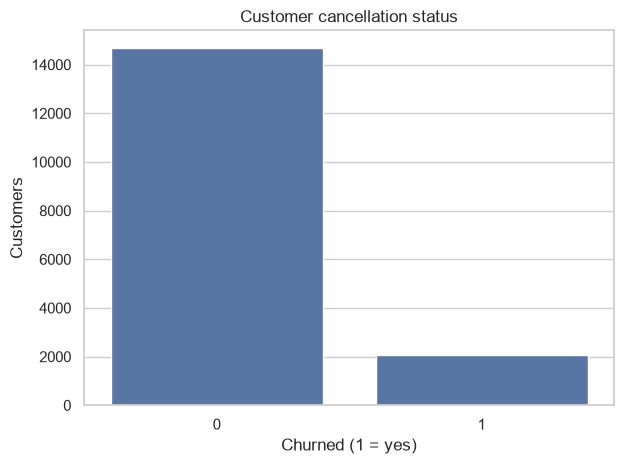

In [66]:
sns.countplot(x="Churned", data=loyalty_df)
plt.title("Customer cancellation status")
plt.xlabel("Churned (1 = yes)")
plt.ylabel("Customers")
plt.tight_layout()
plt.show()

**Insight:** About 12% of members in this historical dataset cancelled, so churn is a minority outcome.

**Business action:** Use risk scores to focus retention outreach rather than contacting every member.

## Feature Engineering
Aggregate monthly activity into customer-level flight, distance, and points features.

In [68]:
flight_features = flight_df.groupby("Loyalty Number").agg(
    total_flights=("Total Flights", "sum"),
    total_distance=("Distance", "sum"),
    total_points_accumulated=("Points Accumulated", "sum"),
    total_points_redeemed=("Points Redeemed", "sum"),
    total_redeem_cost=("Dollar Cost Points Redeemed", "sum"),
    active_months=("Month", "nunique"),
).reset_index()

flight_features.head(3)

,Loyalty Number,total_flights,total_distance,total_points_accumulated,total_points_redeemed,total_redeem_cost,active_months
0,100018,46,81190,81190.0,1513,272,12
1,100102,51,68918,68918.0,1195,215,12
2,100140,47,72856,72856.0,593,107,12


In [69]:
flight_features["points_redeem_ratio"] = (
    flight_features["total_points_redeemed"]
    / flight_features["total_points_accumulated"].replace(0, np.nan)
)
flight_features["avg_flights_per_active_month"] = (
    flight_features["total_flights"] / flight_features["active_months"].replace(0, np.nan)
)
flight_features = flight_features.fillna(0)

# Keep the customer identifier for later scoring, but exclude it from model inputs.
df = loyalty_df.merge(flight_features, on="Loyalty Number", how="left")
drop_cols = [
    "Loyalty Number",
    "Enrollment Year",
    "Enrollment Month",
    "Cancellation Year",
    "Cancellation Month",
]
df_model = df.drop(columns=drop_cols)
df_model.head(3)

,Country,Province,City,Postal Code,Gender,Education,Salary,Marital Status,Loyalty Card,CLV,Enrollment Type,Churned,total_flights,total_distance,total_points_accumulated,total_points_redeemed,total_redeem_cost,active_months,points_redeem_ratio,avg_flights_per_active_month
0,Canada,Ontario,Toronto,M2Z 4K1,Female,Bachelor,83236.0,Married,Star,3839.14,Standard,0,37,54525,54525.0,1418,256,12,0.026006,3.083333
1,Canada,Alberta,Edmonton,T3G 6Y6,Male,College,NaN,Divorced,Star,3839.61,Standard,0,58,77487,77487.0,1971,356,12,0.025437,4.833333
2,Canada,British Columbia,Vancouver,V6E 3D9,Male,College,NaN,Single,Star,3839.75,Standard,1,18,24803,24803.0,374,67,12,0.015079,1.500000


## Modeling
Compare balanced Logistic Regression and Random Forest pipelines on a stratified hold-out set.

In [70]:
X = df_model.drop(columns=["Churned"])
y = df_model["Churned"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Training rows:", len(X_train))
print("Test rows:", len(X_test))

Training rows: 13389
Test rows: 3348


In [71]:
num_cols = X_train.select_dtypes(include=["int64", "float64"]).columns.tolist()
cat_cols = X_train.select_dtypes(include=["object", "category", "str"]).columns.tolist()

num_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
cat_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])
preprocessor = ColumnTransformer(transformers=[
    ("num", num_transformer, num_cols),
    ("cat", cat_transformer, cat_cols),
])

log_reg = Pipeline(steps=[
    ("preprocess", preprocessor),
    ("model", LogisticRegression(max_iter=1000, class_weight="balanced")),
])
log_reg.fit(X_train, y_train);

## Evaluation
Compare recall, precision, F1, and ROC-AUC; recall is prioritized for retention outreach.

In [72]:
def evaluate_model(model, X_eval, y_eval):
    predictions = model.predict(X_eval)
    probabilities = model.predict_proba(X_eval)[:, 1]
    scores = {
        "Accuracy": accuracy_score(y_eval, predictions),
        "Precision": precision_score(y_eval, predictions, zero_division=0),
        "Recall": recall_score(y_eval, predictions, zero_division=0),
        "F1": f1_score(y_eval, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_eval, probabilities),
    }
    return scores, probabilities

,Accuracy,Precision,Recall,F1,ROC-AUC
Logistic Regression,0.802,0.363,0.809,0.502,0.875
Random Forest,0.867,0.469,0.559,0.510,0.871


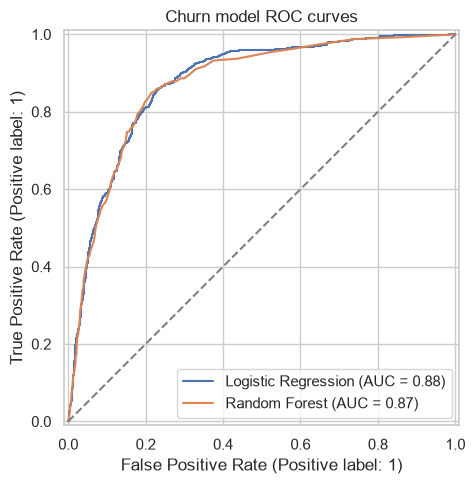

In [73]:
log_reg_metrics, log_prob = evaluate_model(log_reg, X_test, y_test)

rf_model = Pipeline(steps=[
    ("preprocess", preprocessor),
    ("model", RandomForestClassifier(random_state=42, class_weight="balanced")),
])
rf_model.fit(X_train, y_train)
rf_metrics, rf_prob = evaluate_model(rf_model, X_test, y_test)

model_results = {
    "Logistic Regression": log_reg_metrics,
    "Random Forest": rf_metrics,
}
metrics_table = pd.DataFrame(model_results).T
display(metrics_table.round(3))

plt.figure(figsize=(7, 5))
RocCurveDisplay.from_predictions(y_test, log_prob, name="Logistic Regression", ax=plt.gca())
RocCurveDisplay.from_predictions(y_test, rf_prob, name="Random Forest", ax=plt.gca())
plt.plot([0, 1], [0, 1], linestyle="--", color="gray")
plt.title("Churn model ROC curves")
plt.tight_layout()
plt.show()

## Insights
Identify activity segments with elevated historical churn, recommend a model, and export ranked hold-out risk scores.

In [74]:
feature_names = rf_model.named_steps["preprocess"].get_feature_names_out()
importances = rf_model.named_steps["model"].feature_importances_
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances,
}).sort_values("Importance", ascending=False)
importance_df.head(10)

,Feature,Importance
2,num__total_flights,0.171010
3,num__total_distance,0.125376
9,num__avg_flights_per_active_month,0.111534
4,num__total_points_accumulated,0.092273
1,num__CLV,0.056579
6,num__total_redeem_cost,0.055347
8,num__points_redeem_ratio,0.052869
5,num__total_points_redeemed,0.047394
0,num__Salary,0.047296
114,cat__Marital Status_Married,0.008496


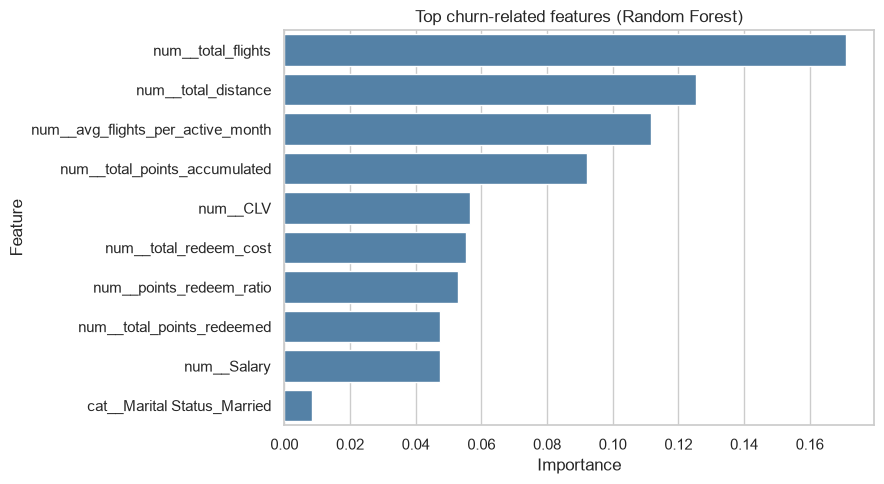

In [75]:
plt.figure(figsize=(9, 5))
sns.barplot(
    x="Importance",
    y="Feature",
    data=importance_df.head(10),
    color="steelblue",
)
plt.title("Top churn-related features (Random Forest)")
plt.tight_layout()
plt.show()

**Insight:** Flight count, distance, monthly flight pace, and points activity are among the strongest overall model signals; feature importance does not explain an individual prediction.

**Business action:** Start with flight-engagement and points-use campaigns, then measure response before scaling.

In [76]:
activity_measures = {
    "total_flights": "Total flights",
    "avg_flights_per_active_month": "Flights per active month",
    "total_distance": "Total distance",
}
segment_rows = []
for feature, measure in activity_measures.items():
    cutoff = df[feature].median()
    for segment, mask in (
        ("Lower activity", df[feature] <= cutoff),
        ("Higher activity", df[feature] > cutoff),
    ):
        segment_rows.append({
            "Activity measure": measure,
            "Segment": segment,
            "Customers": int(mask.sum()),
            "Churn rate (%)": round(df.loc[mask, "Churned"].mean() * 100, 1),
        })
segment_summary = pd.DataFrame(segment_rows)
display(segment_summary)

recommended_name = max(
    model_results,
    key=lambda name: (model_results[name]["Recall"], model_results[name]["ROC-AUC"]),
)
recommended_metrics = model_results[recommended_name]
rate_gaps = {}
for measure in activity_measures.values():
    rates = segment_summary.set_index(["Activity measure", "Segment"])["Churn rate (%)"]
    rate_gaps[measure] = rates.loc[(measure, "Lower activity")] - rates.loc[(measure, "Higher activity")]
target_measure = max(rate_gaps, key=rate_gaps.get)
target_gap = rate_gaps[target_measure]
target_rows = segment_summary[
    (segment_summary["Activity measure"] == target_measure)
    & (segment_summary["Segment"].isin(["Lower activity", "Higher activity"]))
].set_index("Segment")

print(
    f"Recommended model: {recommended_name} "
    f"(churn recall {recommended_metrics['Recall']:.1%}; "
    f"ROC-AUC {recommended_metrics['ROC-AUC']:.3f})."
)
print(
    f"Target lower-activity members by {target_measure.lower()}: "
    f"their observed churn rate is {target_rows.loc['Lower activity', 'Churn rate (%)']:.1f}% "
    f"versus {target_rows.loc['Higher activity', 'Churn rate (%)']:.1f}% for higher-activity members "
    f"(gap {target_gap:.1f} percentage points)."
)
print("Use predicted churn risk to prioritize outreach within this segment; validate offer economics before launch.")

,Activity measure,Segment,Customers,Churn rate (%)
0,Total flights,Lower activity,8825,21.8
1,Total flights,Higher activity,7912,1.8
2,Flights per active month,Lower activity,8782,21.8
3,Flights per active month,Higher activity,7955,1.9
4,Total distance,Lower activity,8369,22.8
5,Total distance,Higher activity,8368,1.9


Recommended model: Logistic Regression (churn recall 80.9%; ROC-AUC 0.875).
Target lower-activity members by total distance: their observed churn rate is 22.8% versus 1.9% for higher-activity members (gap 20.9 percentage points).
Use predicted churn risk to prioritize outreach within this segment; validate offer economics before launch.


**Insight:** In this dataset, members below the median total distance had 22.8% historical churn, compared with 1.9% above the median.

**Business action:** Prioritize low-activity members for engagement, and rank high-CLV customers first within each risk tier.

In [77]:
recommended_prob = log_prob if recommended_name == "Logistic Regression" else rf_prob
scored_customers = df.loc[X_test.index, ["Loyalty Number", "CLV"]].copy()
scored_customers["Actual churn"] = y_test
scored_customers["Churn probability"] = recommended_prob
scored_customers["Risk tier"] = pd.cut(
    recommended_prob,
    bins=[-np.inf, 0.4, 0.7, np.inf],
    labels=["Low Risk", "Medium Risk", "High Risk"],
    include_lowest=True,
)
action_by_tier = {
    "Low Risk": "Standard engagement; no immediate offer",
    "Medium Risk": "Personalized flight deal or points offer",
    "High Risk": "Priority outreach; contact high-CLV members first",
}
scored_customers["Recommended action"] = scored_customers["Risk tier"].map(action_by_tier)
scored_customers = scored_customers.sort_values(
    ["Churn probability", "CLV"], ascending=[False, False]
)

display(pd.DataFrame({
    "Risk tier": ["Low Risk", "Medium Risk", "High Risk"],
    "Churn probability": ["Below 40%", "40% to 70%", "Above 70%"],
    "Recommended action": [action_by_tier[tier] for tier in ["Low Risk", "Medium Risk", "High Risk"]],
}))

chosen_threshold = 0.35
threshold_rows = []
for threshold in [0.50, chosen_threshold]:
    predictions = (recommended_prob >= threshold).astype(int)
    threshold_rows.append({
        "Threshold": threshold,
        "Customers flagged": int(predictions.sum()),
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1": f1_score(y_test, predictions, zero_division=0),
    })
threshold_results = pd.DataFrame(threshold_rows).set_index("Threshold")
display(threshold_results.round(3))
print(
    f"Using {chosen_threshold:.2f} instead of 0.50 favors finding more churners; "
    "review outreach capacity and offer cost before using it in a live campaign."
)

scored_customers["Contact at chosen threshold"] = (
    scored_customers["Churn probability"] >= chosen_threshold
)

avg_customer_value = 500
retention_offer_cost = 50
retention_success_rate = 0.20
high_risk = scored_customers[scored_customers["Risk tier"] == "High Risk"]
expected_saved_customers = (
    len(high_risk) * high_risk["Actual churn"].mean() * retention_success_rate
)
expected_revenue_saved = expected_saved_customers * avg_customer_value
campaign_cost = len(high_risk) * retention_offer_cost
expected_net_gain = expected_revenue_saved - campaign_cost
historical_high_risk_churners = len(high_risk) * high_risk["Actual churn"].mean()
break_even_success_rate = campaign_cost / (
    historical_high_risk_churners * avg_customer_value
)
roi_summary = pd.DataFrame({
    "Measure": ["High-risk customers", "Expected customers retained", "Assumed revenue saved (₹)", "Campaign cost (₹)", "Illustrative net gain (₹)", "Break-even retention success rate (%)"],
    "Estimate": [len(high_risk), round(expected_saved_customers, 1), round(expected_revenue_saved), campaign_cost, round(expected_net_gain), round(break_even_success_rate * 100, 1)],
})
display(roi_summary)
print("ROI is a what-if simulation using assumptions, not a forecast or actual airline result.")

output_dir = next(
    (folder for folder in (Path("outputs"), Path("../outputs")) if folder.is_dir()),
    Path.cwd(),
)
output_path = output_dir / "airline_churn_predictions.csv"
scored_customers.to_csv(output_path, index=False)
print(f"Saved hold-out risk scores to {output_path}.")
display(scored_customers.head(10).round({"Churn probability": 3}))

,Risk tier,Churn probability,Recommended action
0,Low Risk,Below 40%,Standard engagement; no immediate offer
1,Medium Risk,40% to 70%,Personalized flight deal or points offer
2,High Risk,Above 70%,Priority outreach; contact high-CLV members first


,Customers flagged,Accuracy,Precision,Recall,F1
Threshold,,,,,
0.50,919,0.802,0.363,0.809,0.502
0.35,1178,0.743,0.310,0.884,0.459


Using 0.35 instead of 0.50 favors finding more churners; review outreach capacity and offer cost before using it in a live campaign.


,Measure,Estimate
0,High-risk customers,648.0
1,Expected customers retained,54.6
2,Assumed revenue saved (₹),27300.0
3,Campaign cost (₹),32400.0
4,Illustrative net gain (₹),-5100.0
5,Break-even retention success rate (%),23.7


ROI is a what-if simulation using assumptions, not a forecast or actual airline result.
Saved hold-out risk scores to ..\outputs\airline_churn_predictions.csv.


,Loyalty Number,CLV,Actual churn,Churn probability,Risk tier,Recommended action,Contact at chosen threshold
1433,613709,5770.68,0,0.948,High Risk,Priority outreach; contact high-CLV members first,True
2166,741657,7542.71,0,0.948,High Risk,Priority outreach; contact high-CLV members first,True
3394,766012,12877.78,1,0.946,High Risk,Priority outreach; contact high-CLV members first,True
3357,343884,12515.18,0,0.944,High Risk,Priority outreach; contact high-CLV members first,True
4332,651210,2813.51,1,0.944,High Risk,Priority outreach; contact high-CLV members first,True
10584,496052,2458.75,1,0.943,High Risk,Priority outreach; contact high-CLV members first,True
5366,126148,3732.57,1,0.942,High Risk,Priority outreach; contact high-CLV members first,True
183,914255,4217.86,1,0.941,High Risk,Priority outreach; contact high-CLV members first,True
5534,889964,3954.34,1,0.941,High Risk,Priority outreach; contact high-CLV members first,True
2599,318845,8489.84,1,0.940,High Risk,Priority outreach; contact high-CLV members first,True
